# Claimly: Docling ingestion experiment

PDF / JPEG / PNG → validation → one reused standard Docling converter with English CPU RapidOCR → conversion/quality checks → **content relevance** → reviewed internal JSON + canonical pages + source-linked chunks.

This notebook implements the **export-only Phase 1 milestone**. It does not call a paid model, generate embeddings, create Vault rows, or implement a chatbot. Production changes require the separate approval in [NEXT_CONVERSATION.md](NEXT_CONVERSATION.md).

The previous unexecuted direct-model starter is preserved without modification in [parsing_tests.legacy.ipynb](.local/archive/parsing_tests.legacy.ipynb). It is archived because [DOCLING_PLAN.md](DOCLING_PLAN.md) selects the Docling path. Shared contracts stay unchanged.

## 1. Environment and pinned versions

Use the kernel from `services/llm/.venv/bin/python`. From the project root:

```sh
python3 -m venv services/llm/.venv
services/llm/.venv/bin/python -m pip install -r services/llm/parsing/requirements.lock.txt
services/llm/.venv/bin/python services/llm/parsing/prefetch_models.py
services/llm/.venv/bin/python -m ipykernel install --user --name claimly-docling --display-name 'Claimly Docling'
```

Select **Claimly Docling** after registering the kernel. Prefetch is an explicit network operation. Opening or importing this notebook installs nothing. Conversion cells use offline prefetched artifacts. The user-provided `docling-main/` source checkout declares version 2.150.1, matching this experiment's installed release; no editable install or upstream source modification is required.

In [1]:
from pathlib import Path
import json
import os
import sys
from time import perf_counter

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
LAB = PROJECT_ROOT / 'services/llm/parsing'
if str(LAB) not in sys.path:
    sys.path.insert(0, str(LAB))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
from ingestion_lab import (versions, validate_bytes, InvalidSource, make_converter, make_chunker,
    ingest, review_and_export, canonical_pages, evidence_resolves, json_hash, digest, check_manifest)
from run_lab import load_config, fixture_quality_review

print('Python:', sys.version.split()[0])
print('Executable:', Path(sys.executable).relative_to(PROJECT_ROOT))
print(json.dumps(versions(), indent=2))
assert (LAB / '.models/assets.json').exists(), 'Run prefetch_models.py explicitly first.'
config = load_config()
print('Configuration:', json.dumps(config.identity(), indent=2))

Python: 3.13.2
Executable: services/llm/.venv/bin/python
{
  "docling": "2.150.1",
  "docling-core": "2.107.0",
  "docling-ibm-models": "4.0.4",
  "docling-parse": "7.26.0",
  "rapidocr": "3.10.0",
  "onnxruntime": "1.32.0",
  "torch": "2.15.0",
  "transformers": "5.23.0",
  "pillow": "13.0.0",
  "pypdf": "7.1.0"
}
Configuration: {
  "tokenizer_revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
  "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
  "max_tokens": 240,
  "force_full_page_ocr": false,
  "ocr_language": "en",
  "threads": 4,
  "assets_hash": "eebf9e94341feb3bc07775149e6eccc643c9e81e9dbbfa4f17af6255dfa9055a",
  "document_timeout": 120.0
}


## 2. Source bytes, validation, identity and preview

The default is an authored fictional warranty. Change `INPUT_PATH` for another file. Identity is a deterministic test UUID derived from the original SHA-256; production supplies Backend identity and ownership. Limits are 10 MiB and 25 pages. PDF encryption, decoding errors, animated images and unsupported signatures stop before Docling. EXIF normalization makes a separate lossless PNG at the original resolution; original bytes stay unchanged. HEIC needs export to a supported format.

Folder and filename are **not classifier inputs**. The 16-folder sample manifest records them for sampling/audit only.

{
  "document_id": "c288883d-2a7f-5c05-a52a-5e6791221b30",
  "document_version": 1,
  "filename": "warranty.pdf",
  "mime_type": "application/pdf",
  "sha256": "6122f9d2bec2a2cde646b8bfed08a3e2ae1f04a5315c902ce019b892a66cda1e",
  "page_count": 1,
  "preparation": "original bytes"
}


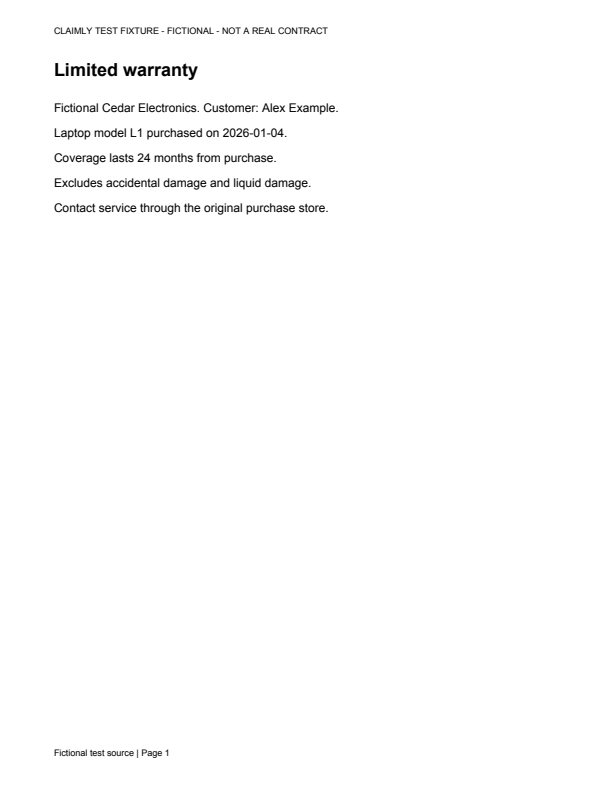

In [2]:
INPUT_PATH = LAB / 'fixtures/warranty.pdf'
DOCUMENT_VERSION = 1
OUTPUT_ROOT = LAB / 'runs/notebook-demo'
input_bytes = INPUT_PATH.read_bytes()
source = validate_bytes(input_bytes, INPUT_PATH.name, document_version=DOCUMENT_VERSION)
print(json.dumps(source.identity(), indent=2))
assert source.original == input_bytes and digest(input_bytes) == source.sha256
from IPython.display import display
from PIL import Image
from io import BytesIO
if source.mime_type == 'application/pdf':
    import pypdfium2 as pdfium
    with pdfium.PdfDocument(source.original) as preview_pdf:
        display(preview_pdf[0].render(scale=1).to_pil())
else:
    display(Image.open(BytesIO(source.prepared)))

## 3. Configure once and convert

Both allowed formats use the same standard pipeline options: CPU, layout, accurate table structure, English RapidOCR, orientation recovery, generated page images, and a 120-second document timeout. Default OCR retains native PDF text; full-page OCR is a separate explicit retry setting. No VLM pipeline or DocumentExtractor is used.

Models and tokenizer were prefetched. Converter reuse avoids loading weights for every file. Initialization timing below excludes Python imports; conversion timing includes first-use model initialization when applicable.

In [3]:
if 'converter' not in globals() or globals().get('converter_config') != config:
    started = perf_counter()
    converter = make_converter(config)
    chunker = make_chunker(config)
    converter_config = config
    print('Converter/tokenizer initialization seconds:', round(perf_counter() - started, 3))
report, result, canonical, chunks = ingest(input_bytes, INPUT_PATH.name, converter, chunker,
    config, OUTPUT_ROOT, document_id=source.document_id, document_version=source.document_version)
print(json.dumps({k: report.get(k) for k in ['validation','conversion_status','conversion_seconds',
      'quality','relevance','review_state','acceptance_gate','processing_error']}, indent=2))
assert chunks == [], 'No accepted export before a matching quality review.' 

services/llm/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Converter/tokenizer initialization seconds: 3.487


W1115 03:52:17.966000 8009 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 10528.90it/s]


{
  "validation": "valid",
  "conversion_status": "success",
  "conversion_seconds": 3.2182867920491844,
  "quality": {
    "passed": true,
    "conversion_status": "success",
    "errors": [],
    "warnings": [],
    "page_checks": [
      {
        "page": 1,
        "state": "text",
        "characters": 335,
        "has_page_image": true
      }
    ],
    "visual_review": "required separately; structural checks do not prove OCR completeness or fact correctness"
  },
  "relevance": {
    "outcome": "relevant",
    "reason": "Supported document title and substantive terms found in readable content.",
    "category": "warranty",
    "evidence": [
      {
        "page": 1,
        "quote": "Limited warranty"
      }
    ],
    "policy_version": "claimly-content-rules-v1-experimental",
    "method": "content-rule-baseline"
  },
  "review_state": "quality_review_required",
  "acceptance_gate": false,
  "processing_error": null
}


## 4. Inspect status, pages, tables and provenance

Status/errors are checked before the helper consumes `result.document`. Partial conversion, page gaps, provenance gaps, sparse/garbled text, and logged conversion warnings fail the quality gate. Uniformly white pages are recorded as blank; nonblank pages with no text are unreadable. These tests cannot prove every OCR character is right.

Compare the original preview with the converted page and text below. A model confidence score does not verify a date, amount, exclusion, or business meaning.

PAGE 1 | needs_review=False
CLAIMLY TEST FIXTURE - FICTIONAL - NOT A REAL CONTRACT
Limited warranty
Fictional Cedar Electronics. Customer: Alex Example. Laptop model L1 purchased on 2026-01-04. Coverage lasts 24 months from purchase. Excludes accidental damage and liquid damage.
Contact service through the original purchase store.
Fictional test source | Page 1


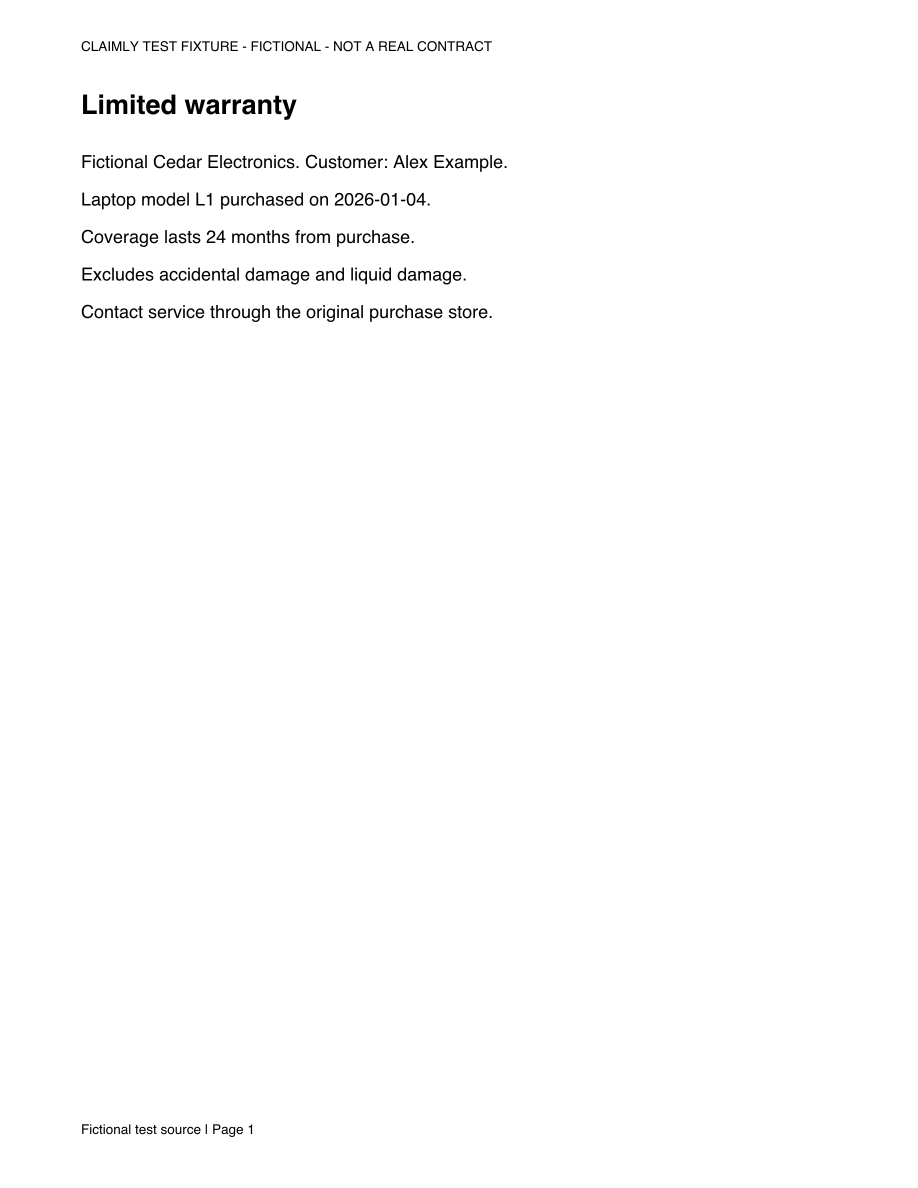

Tables: 0 Text items: 5
Source mappings: [
  {
    "item_ref": "#/texts/0",
    "page": 1,
    "start": 0,
    "end": 54,
    "text": "CLAIMLY TEST FIXTURE - FICTIONAL - NOT A REAL CONTRACT",
    "method": "docling-text-charspan",
    "source_charspan": [
      0,
      54
    ],
    "content_layer": "furniture",
    "source_locations": [
      {
        "page": 1,
        "bbox": {
          "l": 54.0,
          "t": 764.462,
          "r": 328.041,
          "b": 756.137,
          "coord_origin": "BOTTOMLEFT"
        }
      }
    ]
  },
  {
    "item_ref": "#/texts/1",
    "page": 1,
    "start": 55,
    "end": 71,
    "text": "Limited warranty",
    "method": "docling-text-charspan",
    "source_charspan": [
      0,
      16
    ],
    "content_layer": "body",
    "source_locations": [
      {
        "page": 1,
        "bbox": {
          "l": 54.0,
          "t": 728.924,
          "r": 198.03600000000006,
          "b": 712.274,
          "coord_origin": "BOTTOMLEFT"
        }

In [4]:
if canonical is not None:
    for page in canonical['pages']:
        print(f"PAGE {page['page']} | needs_review={page['needs_review']}")
        print(page['text'])
        image = result.document.pages.get(page['page'])
        if image is not None and image.image is not None:
            display(image.image.pil_image)
    print('Tables:', len(result.document.tables), 'Text items:', len(result.document.texts))
    print('Source mappings:', json.dumps(canonical['item_map'][:3], indent=2))
else:
    print('No consumable document; inspect conversion diagnostics above.')

## 4a. Content relevance and admission

The transparent **experimental content-rule baseline** recognizes supported titles plus substantive terms, rejects recognized standalone unrelated content, and sends unrecognized/ambiguous content to review. It is limited and must not be treated as a production semantic classifier. Embedded instructions trigger review and cannot force acceptance. A relevant bill does not need a due date or explicit benefit.

Quality, relevance and admission are separate. The baseline receives only canonical page text. A quality review cannot override unrelated content, conversion errors, or source mapping gaps.

The supplied `docs-sm` labels are **Codex visual-review proposals**, and synthetic labels are fixture-author ground truth. Neither is represented as human-reviewed. All are excluded from scored held-out metrics until a person reviews them. Do not set `human_reviewed` merely to obtain a score.

In [5]:
manifest = json.loads((LAB / 'evaluation_manifest.json').read_text())
cases = manifest['cases']
check_manifest(cases, LAB)
print('Cases:', len(cases), '| docs-sm smoke:', sum(c['folder'] != 'supplemental' for c in cases))
print('Current content decision:', report['relevance'])
print('Current export gate:', report['acceptance_gate'])
print('Labels awaiting human review:', sum(not c['human_reviewed'] for c in cases))

Cases: 55 | docs-sm smoke: 16
Current content decision: {'outcome': 'relevant', 'reason': 'Supported document title and substantive terms found in readable content.', 'category': 'warranty', 'evidence': [{'page': 1, 'quote': 'Limited warranty'}], 'policy_version': 'claimly-content-rules-v1-experimental', 'method': 'content-rule-baseline'}
Current export gate: False
Labels awaiting human review: 55


## 5. Review and export the same in-memory document

For the fictional fixtures only, the helper can check **every authored body passage plus header and footer** against canonical text. Missing passages block export. This is an explicit synthetic quality check, not a human relevance label or a substitute for real-source review.

For a custom real file, leave `QUALITY_REVIEW = None` until the original and converted pages have been inspected. A review record must contain `approved`, `reviewer`, `reason`, `source_sha256`, and `canonical_hash`; it is bound to this exact source and conversion. Review/uncertain/unreadable/rejected cases produce diagnostics only.

Accepted checkpoints use a hash-scoped directory with `document.json`, `manifest.json`, `pages.json`, `chunks.jsonl`, and page PNGs. The original file remains at its source path. Export and chunking below use the same in-memory DoclingDocument and do **not rerun OCR**.

In [6]:
case = next((c for c in cases if (LAB / c['relative_path']).resolve() == INPUT_PATH.resolve()
             and c['sha256'] == source.sha256), None)
QUALITY_REVIEW = fixture_quality_review(case, report, canonical) if case else None
# For a visually reviewed real file, explicitly replace None with a review record.
if result is not None and canonical is not None:
    report, chunks = review_and_export(source, result, report, chunker, config,
                                       OUTPUT_ROOT, QUALITY_REVIEW)
print(json.dumps({k:report.get(k) for k in ['relevance','review_state','acceptance_gate',
                'artifact_path','processing_error']}, indent=2).replace(str(PROJECT_ROOT) + '/', ''))
print('Chunks:', len(chunks))

{
  "relevance": {
    "outcome": "relevant",
    "reason": "Supported document title and substantive terms found in readable content.",
    "category": "warranty",
    "evidence": [
      {
        "page": 1,
        "quote": "Limited warranty"
      }
    ],
    "policy_version": "claimly-content-rules-v1-experimental",
    "method": "content-rule-baseline"
  },
  "review_state": "reviewed",
  "acceptance_gate": true,
  "artifact_path": "services/llm/parsing/runs/notebook-demo/accepted/c288883d-2a7f-5c05-a52a-5e6791221b30/1/5f76eea5c6d0f9d712f0bb0107de6ea02f6160d779c782a18a7006e84cf4b763",
  "processing_error": null
}
Chunks: 1


### Reload without OCR

DoclingDocument JSON is an internal conversion checkpoint, not Claimly `ExtractionOutput` or a Vault Entry. The manifest records source identity/hash, resolved versions and pipeline options, OCR settings, serializer/schema version, quality/relevance decisions, review state and timing. Artifact hashes detect corruption before checkpoint reuse.

In [7]:
reloaded = None
if report['acceptance_gate']:
    from docling_core.types.doc import DoclingDocument
    artifact = Path(report['artifact_path'])
    reloaded = DoclingDocument.load_from_json(artifact / 'document.json')
    loaded_pages = canonical_pages(reloaded, source.page_count)
    assert loaded_pages == canonical
    print('JSON reload verified:', artifact.relative_to(LAB))
    print('Saved files:', sorted(p.name for p in artifact.iterdir()))
else:
    print('Checkpoint withheld by admission gate.')

JSON reload verified: services/llm/parsing/runs/notebook-demo/accepted/c288883d-2a7f-5c05-a52a-5e6791221b30/1/5f76eea5c6d0f9d712f0bb0107de6ea02f6160d779c782a18a7006e84cf4b763
Saved files: ['chunks.jsonl', 'document.json', 'manifest.json', 'page-1.png', 'pages.json']


## 6. Canonical Page DTOs and exact evidence

`claimly-pages-v2` preserves body reading order, then records furniture in its Docling order, with layers identified in the item map. Text uses valid Docling per-page character spans. Single-page tables use row-major cells joined by tabs/newlines; spanning tables need explicit mapping review. No PDF byte offsets or inferred chunk offsets are invented.

`pages.json` is an internal envelope. Its `pages` list uses the existing Page DTO unchanged. Character offsets in the item map refer only to these exact serialized strings. Contextualized chunks may repeat headings/table headers and are not guaranteed to be page substrings.

In [8]:
if canonical is not None:
    from jsonschema import Draft202012Validator
    contract = json.loads((PROJECT_ROOT / 'Claimly_Three_Parts/contracts/llm.openapi.json').read_text())
    for page in canonical['pages']:
        Draft202012Validator(contract['components']['schemas']['Page']).validate(page)
    if canonical['item_map']:
        span = canonical['item_map'][0]
        evidence = {'document_id': source.document_id, 'document_version': source.document_version,
                    'page': span['page'], 'quote': span['text']}
        Draft202012Validator(contract['components']['schemas']['EvidenceRef']).validate(evidence)
        assert evidence_resolves(evidence, source, canonical)
        print('Evidence resolves:', evidence)

Evidence resolves: {'document_id': 'c288883d-2a7f-5c05-a52a-5e6791221b30', 'document_version': 1, 'page': 1, 'quote': 'CLAIMLY TEST FIXTURE - FICTIONAL - NOT A REAL CONTRACT'}


## 7. Structure-aware HybridChunker

The pinned MiniLM tokenizer supports the proposed embedding model, but no embedding weights or vectors are used. The initial 240-token contextualized budget leaves room below the model's 256-token sequence limit. It is an initial setting, not a claimed optimum.

Each own chunk record keeps identity, source text and separate contextualized text, all contributing item/page/bounding-box references, canonical item spans, headings, order, text hash, and neighbor links. HybridChunker repeats table headers; a source item can contribute to several chunks. Multi-page table ambiguity and oversized contextualized output block export. Neighbor links preserve access to qualifying clauses and exclusions.

In [9]:
if chunks:
    print(json.dumps(chunks[0], indent=2))
    for chunk in chunks:
        assert chunker.tokenizer.count_tokens(chunk['contextualized_text']) <= config.max_tokens
        assert chunk['source_locations'] and chunk['item_refs']
        for span in chunk['canonical_spans']:
            assert span['page'] in {p['page'] for p in canonical['pages']}
    from ingestion_lab import build_chunks
    rebuilt = build_chunks(reloaded, source, canonical, chunker, report['run_key'], config)
    assert [c['chunk_id'] for c in rebuilt] == [c['chunk_id'] for c in chunks]
    print('Rebuilt identical chunk IDs from JSON without OCR.')
else:
    print('No ordinary retrieval chunks for this case.')

{
  "chunk_id": "29184fd47fab6013648c4b3e2c4aed61baf89304a6aaad601a164ed4b49a5b3e",
  "processing_id": "5f76eea5c6d0f9d712f0bb0107de6ea02f6160d779c782a18a7006e84cf4b763",
  "serializer_version": "claimly-pages-v2",
  "document_id": "c288883d-2a7f-5c05-a52a-5e6791221b30",
  "document_version": 1,
  "source_sha256": "6122f9d2bec2a2cde646b8bfed08a3e2ae1f04a5315c902ce019b892a66cda1e",
  "source_text": "Fictional Cedar Electronics. Customer: Alex Example. Laptop model L1 purchased on 2026-01-04. Coverage lasts 24 months from purchase. Excludes accidental damage and liquid damage.\nContact service through the original purchase store.",
  "contextualized_text": "Limited warranty\nFictional Cedar Electronics. Customer: Alex Example. Laptop model L1 purchased on 2026-01-04. Coverage lasts 24 months from purchase. Excludes accidental damage and liquid damage.\nContact service through the original purchase store.",
  "item_refs": [
    "#/texts/2",
    "#/texts/3"
  ],
  "source_locations": [
   

### Exact-phrase retrieval smoke check

Find a known phrase and its adjacent exclusions in admitted chunks, then resolve the quote against canonical text. This checks lexical candidates and citations; it does not establish semantic recall or production session isolation.

In [10]:
if chunks and case and case['source_group'] == 'warranty':
    phrase = 'Coverage lasts 24 months from purchase.'
    hits = [c for c in chunks if phrase in c['source_text']
            and c['document_id'] == source.document_id
            and c['document_version'] == source.document_version]
    assert hits, 'Known warranty passage missing from chunk search.'
    refs = [{'document_id': source.document_id, 'document_version': source.document_version,
             'page': p['page'], 'quote': phrase} for p in canonical['pages'] if phrase in p['text']]
    assert refs and all(evidence_resolves(r, source, canonical) for r in refs)
    assert any('Excludes accidental damage and liquid damage.' in c['source_text'] for c in chunks)
    print('Known duration and exclusions found; citations resolve:', refs)

Known duration and exclusions found; citations resolve: [{'document_id': 'c288883d-2a7f-5c05-a52a-5e6791221b30', 'document_version': 1, 'page': 1, 'quote': 'Coverage lasts 24 months from purchase.'}]


## 8. Same configuration, PDF and photo-like JPEG

This JPEG is rasterized from the fictional PDF. It tests the image/OCR path and **does not establish actual phone-photo coverage**. Real phone images with framing, glare and camera metadata remain required before production approval.

In [11]:
photo_path = LAB / 'fixtures/clear_simulated_photo.jpg'
photo_report, photo_result, photo_pages, _ = ingest(photo_path.read_bytes(), photo_path.name,
    converter, chunker, config, OUTPUT_ROOT)
print('JPEG:', photo_report.get('conversion_status'), photo_report['relevance'],
      'seconds:', photo_report.get('conversion_seconds'))
if photo_pages:
    print(photo_pages['pages'][0]['text'])

JPEG: success {'outcome': 'relevant', 'reason': 'Supported document title and substantive terms found in readable content.', 'category': 'warranty', 'evidence': [{'page': 1, 'quote': 'Limited warranty'}], 'policy_version': 'claimly-content-rules-v1-experimental', 'method': 'content-rule-baseline'} seconds: 2.5261529170675203
CLAIMLY TEST FIXTURE - FICTIONAL - NOT A REAL CONTRACT
Limited warranty
Fictional Cedar Electronics. Customer: Alex Example. Laptop model L1 purchased on 2026-01-04. Coverage lasts 24 months from purchase. Excludes accidental damage and liquid damage.
Contact service through the original purchase store.
Fictional test source Page 1 1


In [12]:
warm_report, _, _, _ = ingest(input_bytes, INPUT_PATH.name, converter, chunker, config,
    OUTPUT_ROOT, document_id=source.document_id, document_version=source.document_version)
print('Same-session warm conversion seconds:', warm_report.get('conversion_seconds'))

Same-session warm conversion seconds: 0.27782995789311826


## 9. Bounded corpus evaluation

The saved run uses 55 cases: one sorted file per each of the 16 docs-sm folders, 12 core relevant fixtures, 8 difficult raster/PDF fixtures, 5 unrelated, 5 adversarial, a blank page, and 8 invalid files. Hashes and source groups freeze splits; duplicates/variants stay together. Only the selected 16 corpus images are converted.

The full batch is an explicit CLI operation:

```sh
services/llm/.venv/bin/python services/llm/parsing/run_lab.py --output runs/final
```

Do not use proposed labels to override predictions. The report distinguishes validation, conversion, relevance, quality review, admission, canonical quote checks, timing, process peak RSS, and unresolved cases. Human-reviewed held-out metrics show counts/denominators; absent denominators are `null`, never a perfect score. See [RESULTS.md](RESULTS.md) for measured outcomes and limits.

In [13]:
saved_report = LAB / 'runs/final/run_report.json'
if saved_report.exists():
    batch = json.loads(saved_report.read_text())
    print(json.dumps(batch['metrics'], indent=2))
    print('CASE | CONVERSION | RELEVANCE | ADMITTED | CHUNKS | SECONDS | SCORE')
    for row in batch['runs']:
        print(row['case_id'], row.get('conversion_status','not_run'), row['relevance']['outcome'],
              row['acceptance_gate'], row['chunk_count'], round(row['elapsed_seconds'],3), row['pass_fail'], sep=' | ')
else:
    print('Run the explicit batch command to create a report.')

{
  "held_out_scored": {
    "cases": 0,
    "false_acceptance": {
      "count": 0,
      "denominator": 0,
      "rate": null
    },
    "false_rejection": {
      "count": 0,
      "denominator": 0,
      "rate": null
    },
    "unresolved_relevant": {
      "count": 0,
      "denominator": 0,
      "rate": null
    },
    "review": {
      "count": 0,
      "denominator": 0,
      "rate": null
    },
    "unreadable": {
      "count": 0,
      "denominator": 0,
      "rate": null
    }
  },
  "excluded_unreviewed": 55,
  "invalid_validation": {
    "cases": 8,
    "stopped_before_conversion": 8
  },
  "by_folder": {
    "advertisement": {
      "cases": 0,
      "false_acceptance": {
        "count": 0,
        "denominator": 0,
        "rate": null
      },
      "false_rejection": {
        "count": 0,
        "denominator": 0,
        "rate": null
      },
      "unresolved_relevant": {
        "count": 0,
        "denominator": 0,
        "rate": null
      },
      "review": 

## 10. Export-only boundary and later branches

This milestone stops after validated chunks. No vector database, framework, semantic retrieval score, index ownership mechanism, or answer generation is claimed. Source-linked chunks are ready for a later Backend-owned index. Before that stage, test session/document/version filters, duplicates, updates/deletion, query evidence recall, and adjacent exclusions independently of answer generation.

A separate later field-extraction adapter can send complete canonical pages for short documents or tested multi-part input for long ones. It must return the unchanged `ExtractionOutput`, validate canonical evidence and identity, preserve nulls and valid empty benefits, and leave usage/deadlines to Backend. No configured model adapter is present in this notebook; no Vault row is produced.

Human label review, genuine phone photos, broader language coverage and a stronger semantic relevance classifier remain before requesting Phase 2 production approval.

## 11. Manual review: raw files, text and tokens

The corpus contains **5,000 JPEGs across 16 folders** (302 invoices), OS metadata files excluded. This view inspects only **12 cases**: three corpus invoices, five clear rejection candidates, three correspondence/handwriting review cases, and one fictional supported bill for comparison.

Expand a case to compare the unchanged raw image with full canonical text and MiniLM token pieces. Token counts exclude special tokens; they are not image tokens, OpenAI tokens, or billed usage. Predictions remain experimental, and readable text does not establish relevance.

For Previous/Next navigation, full-size images and manual label/reason capture, open **[manual_review.html](manual_review.html)**. Downloaded reviews remain separate from the evaluation manifest until explicitly checked and merged. Opening this section performs no OCR, paid calls, upload acceptance or indexing. All displayed paths are relative.


5,000 JPEGs | 302 invoices | 12 selected cases



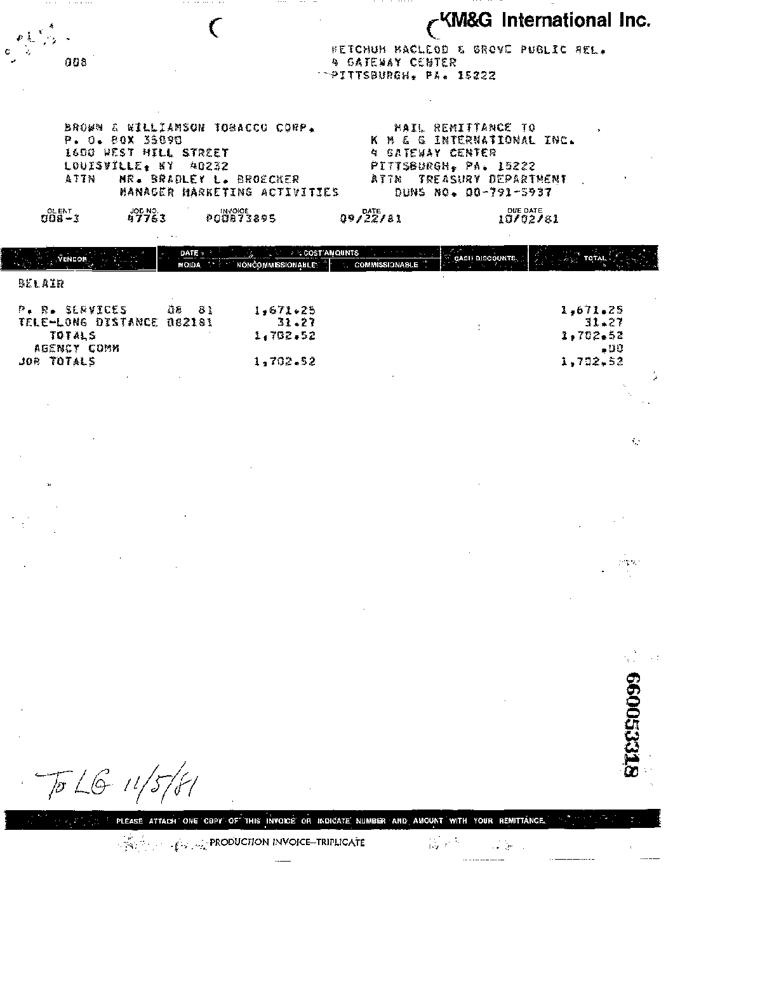
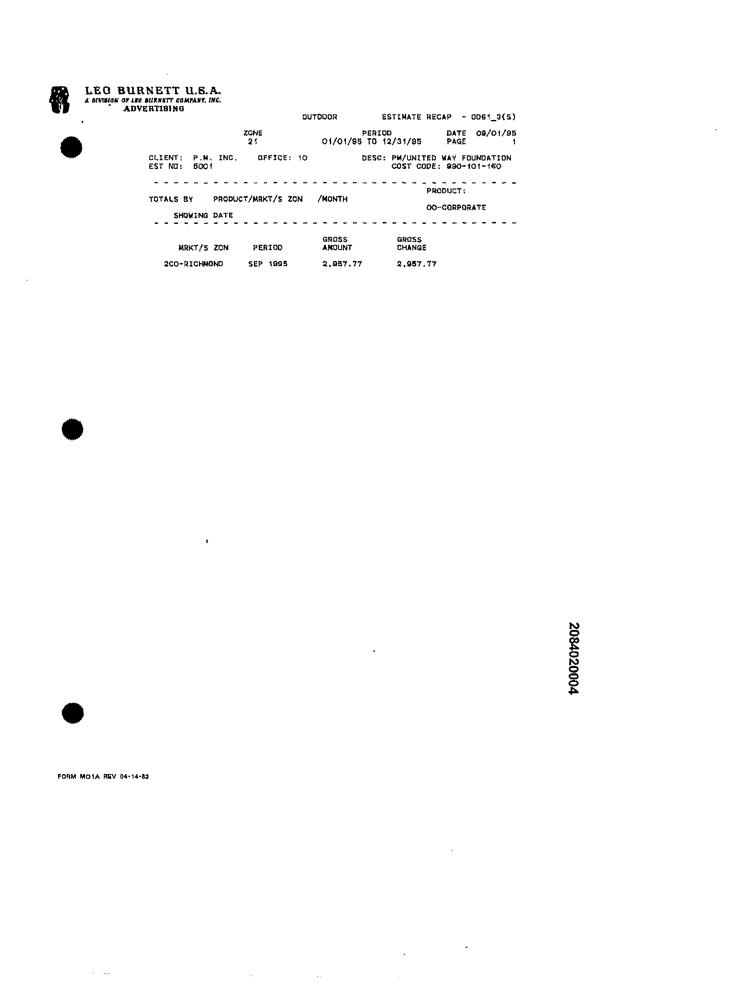
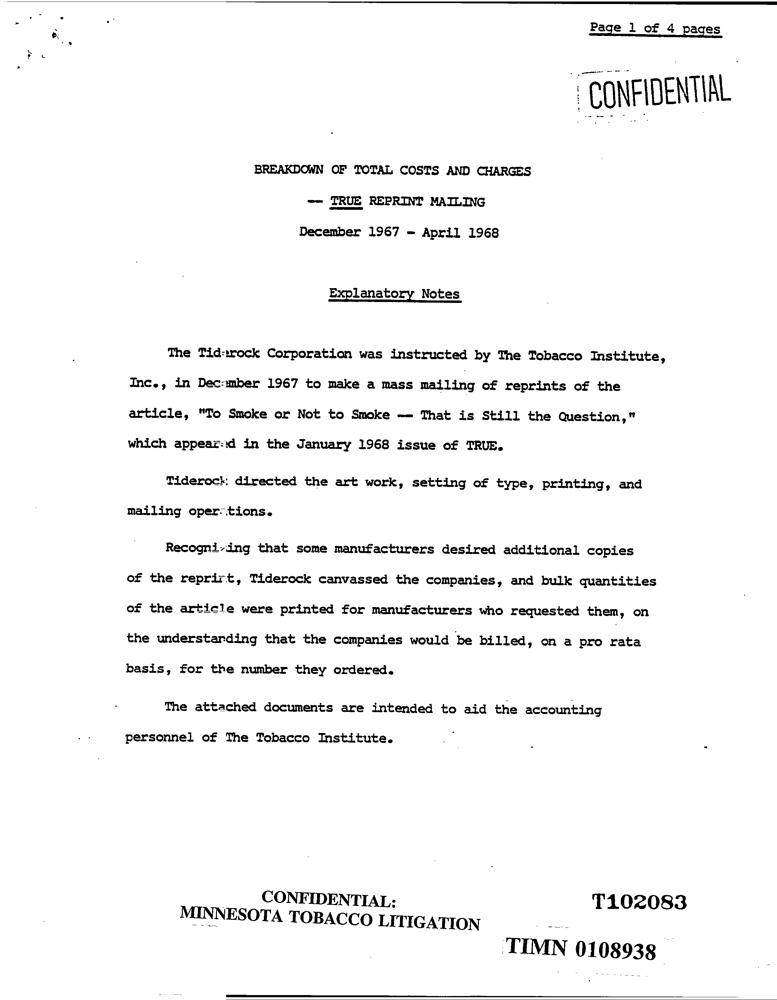
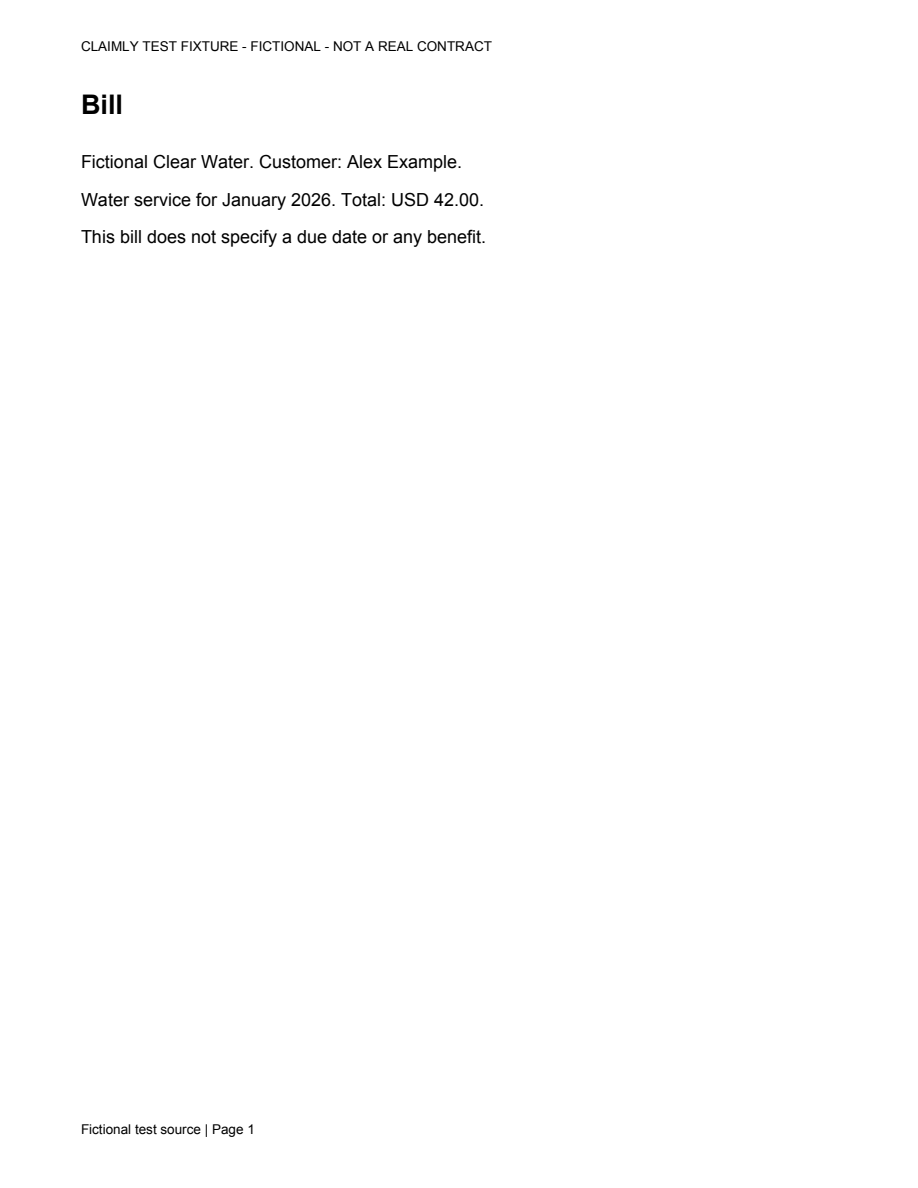
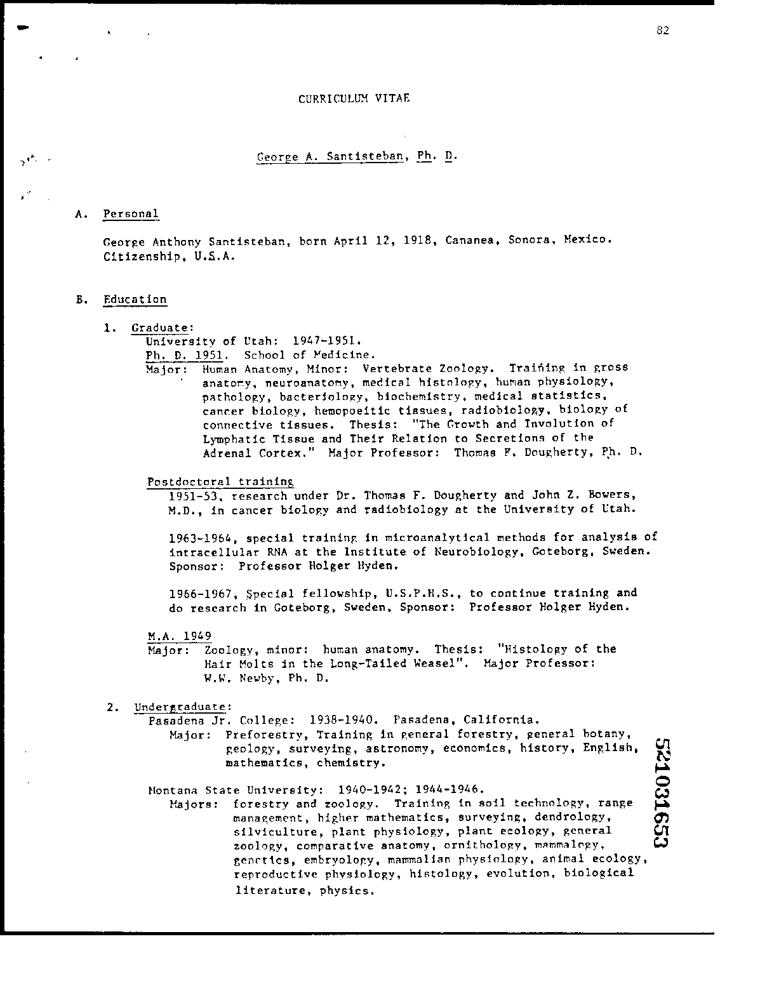
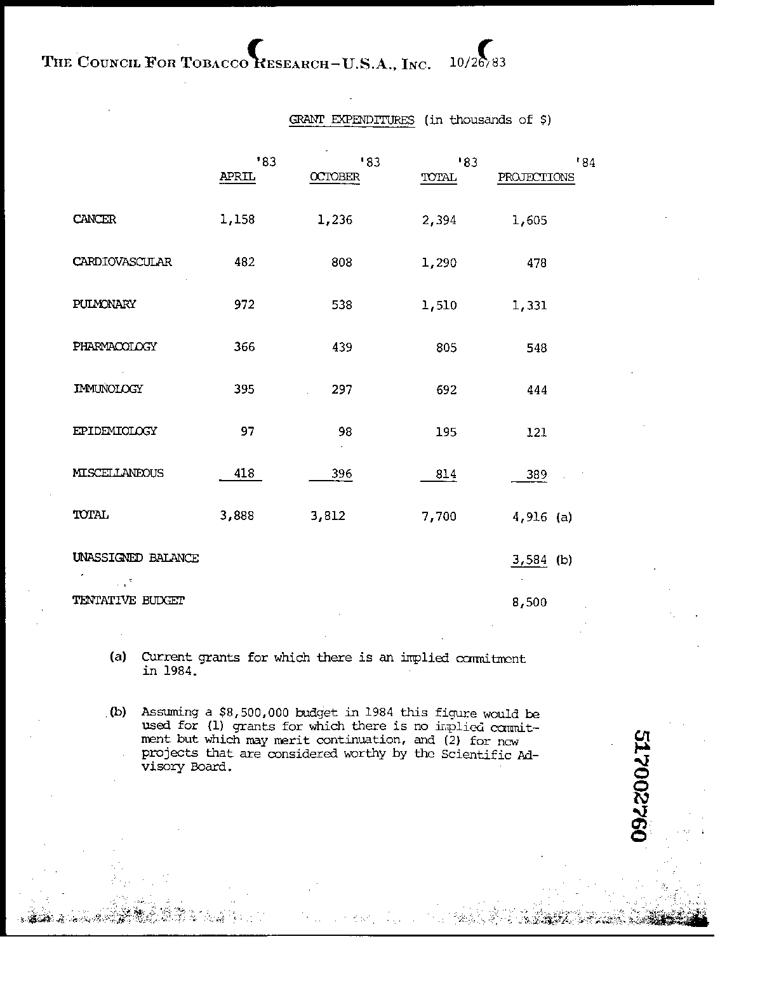
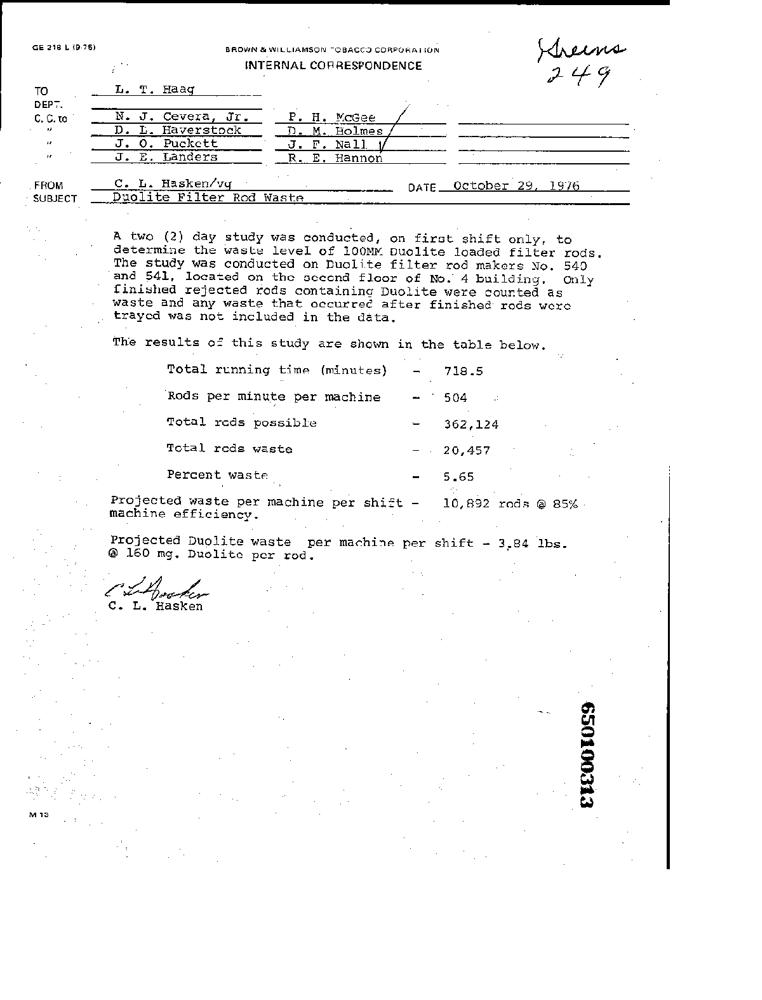
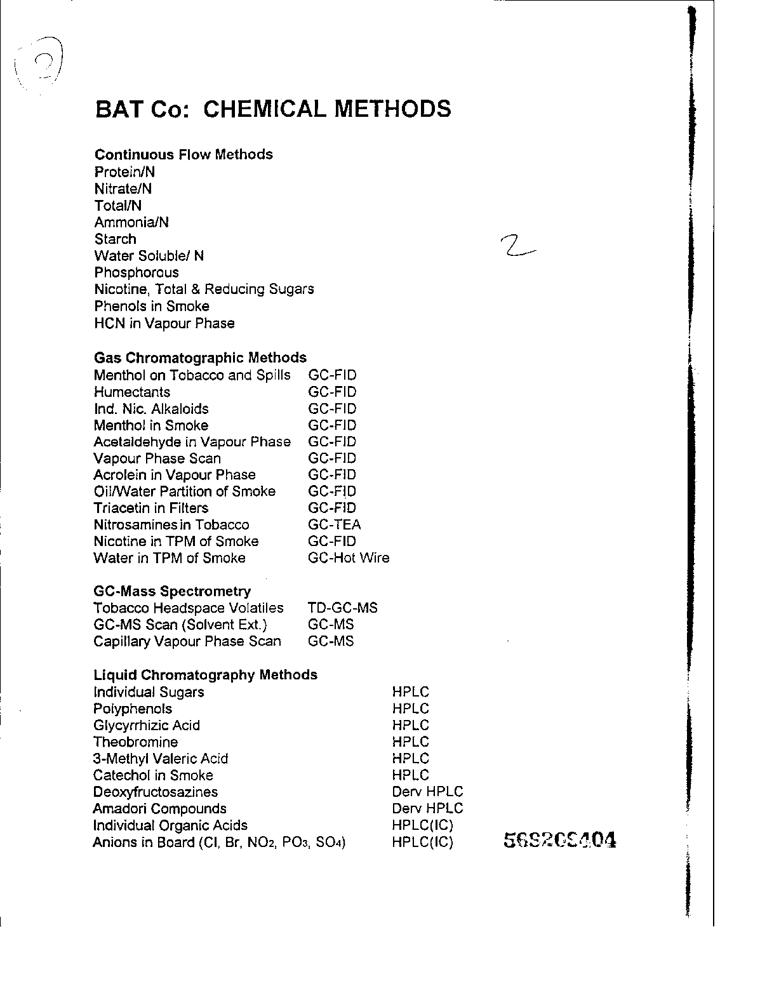
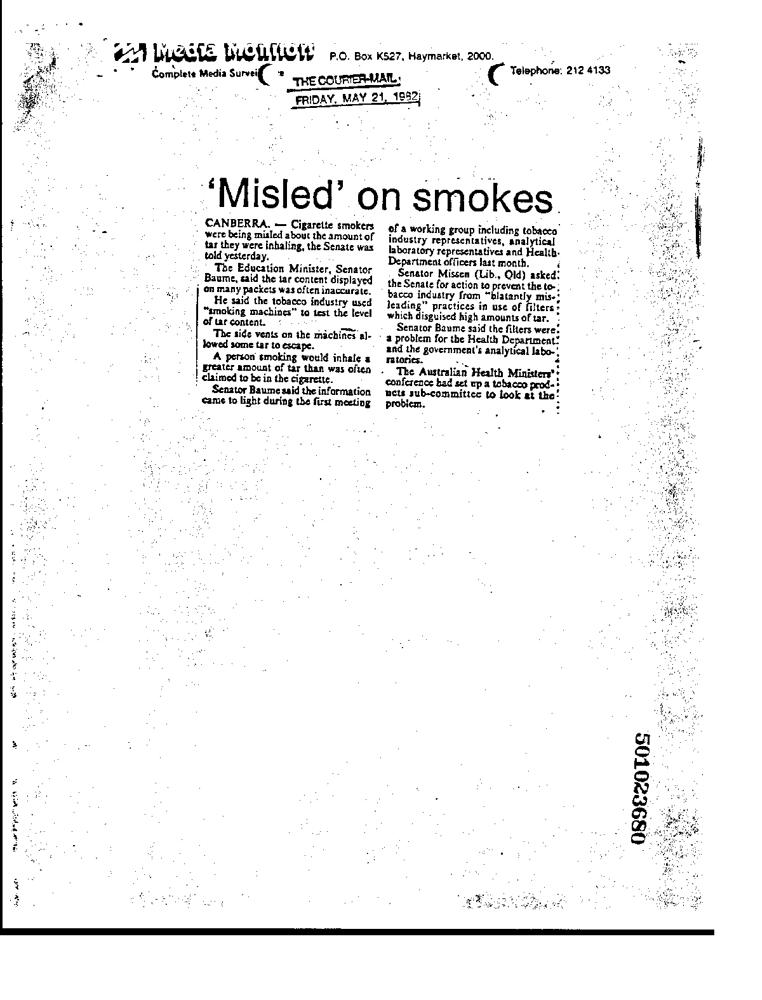
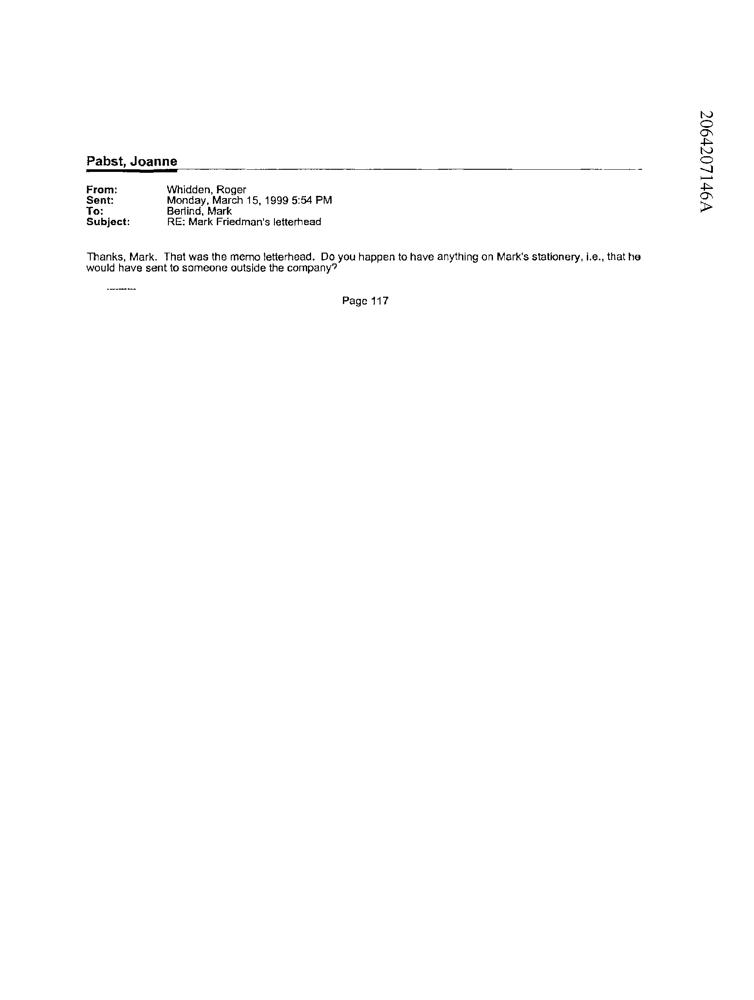
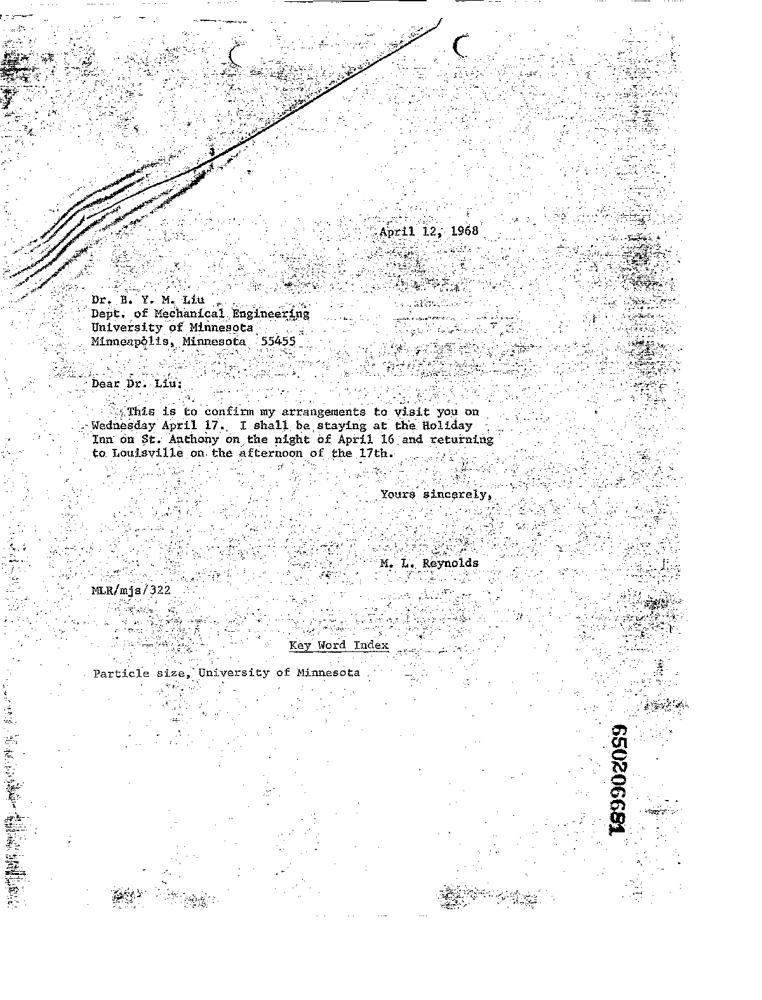
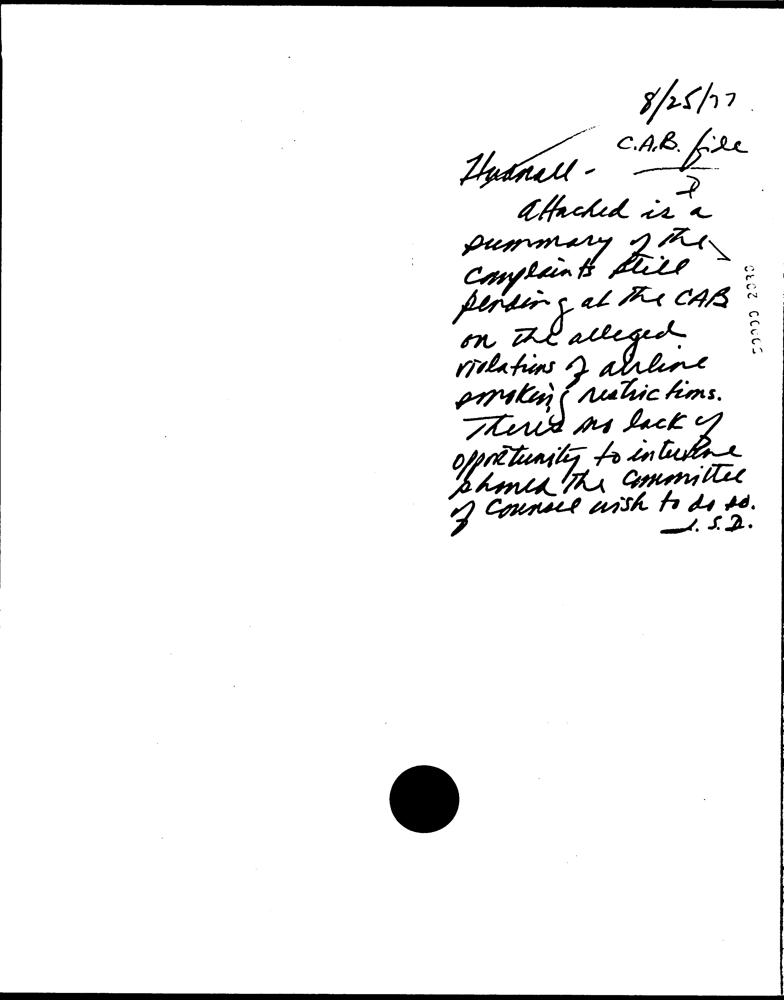

In [1]:
from pathlib import Path
import json
import sys
from IPython.display import HTML, display
review_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
review_lab = review_root / 'services/llm/parsing'
if str(review_lab) not in sys.path:
    sys.path.insert(0, str(review_lab))
from review_gallery import notebook_cards
review_data = json.loads((review_lab / 'runs/manual-review/gallery-data.json').read_text())
print(f"{review_data['image_files']:,} JPEGs | {review_data['invoice_files']} invoices | {len(review_data['cases'])} selected cases")
display(HTML(notebook_cards(review_data)))

## 12. Your completed manual reviews

All 12 reviews have been exported from the browser and preserved exactly in `manual_reviews.json`. This section shows your labels, readability, reasons, reviewer, and timestamps beside the existing predictions. Source hashes are checked before comparison.

The reviews were entered with predictions visible, so matches/differences are descriptive rather than blind held-out accuracy. Earlier batch results predate these reviews. The evaluation manifest and submitted labels remain unchanged while the flagged interpretation questions are resolved.

Your clarification about supplying the next agent with laws, rules, terms, and consumer-protection context is recorded separately in `manual_review_notes.json`. That later deadline assessment is distinct from whether a supported bill is relevant at upload.

Open `review_results.html` for the same comparison plus the raw source/text/token cards. This section performs no OCR or paid calls.


In [1]:
from pathlib import Path
import json
import sys
from IPython.display import HTML, display
results_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
results_lab = results_root / 'services/llm/parsing'
if str(results_lab) not in sys.path:
    sys.path.insert(0, str(results_lab))
from review_results import compare_reviews, review_summary_html
human_export = json.loads((results_lab / 'manual_reviews.json').read_text())
selected_gallery = json.loads((results_lab / 'runs/manual-review/gallery-data.json').read_text())
human_comparison = compare_reviews(human_export, selected_gallery, results_lab)
human_comparison['deadline_context_clarification'] = json.loads((results_lab / 'manual_review_notes.json').read_text())
print(f"{human_comparison['review_count']} source-verified human reviews | {human_comparison['agreement_count']} matches | {human_comparison['disagreement_count']} differences")
display(HTML(review_summary_html(human_comparison)))

12 source-verified human reviews | 5 matches | 7 differences


Source,Your label / readability,Pipeline prediction,Comparison,Your note and follow-up
docs-sm/invoice/0000137486.jpg293 MiniLM text tokens,relevantpartialReviewer: admin,uncertainPrediction reason / qualityBusiness-to-business invoice; consumer relevance is unconfirmed.No conversion warnings recorded.,Different,"The most importantly, the document number and dates are correctThe reason checks OCR accuracy. Confirm Claimly content relevance separately, including whether corporate billing/reprint material is supported.Review timestamp2026-11-14T23:46:45.618Z"
docs-sm/invoice/2084020004.jpg164 MiniLM text tokens,relevantreadableReviewer: admin,unreadablePrediction reason / qualityRapidOCR returned empty result!RapidOCR returned empty result!,Different,"The document number is given correctly, but the part 'PERICO 01/01/95 T012/31/95' should be replace to 'PERIOD 01/01/95 TO 12/31/95'The reason checks OCR accuracy. Confirm Claimly content relevance separately, including whether corporate billing/reprint material is supported.Review timestamp2026-11-14T23:49:53.341Z"
docs-sm/invoice/tob04705.73_tob04705.76.jpg205 MiniLM text tokens,relevantpartialReviewer: admin,uncertainPrediction reason / qualityContent baseline cannot establish Claimly relevance; review required.No conversion warnings recorded.,Different,"Generally all correct, and most importantly dates and the document number areThe reason checks OCR accuracy. Confirm Claimly content relevance separately, including whether corporate billing/reprint material is supported.Review timestamp2026-11-14T23:51:11.234Z"
fixtures/bill.pdf53 MiniLM text tokens,uncertainreadableReviewer: admin,relevantPrediction reason / qualitySupported document title and substantive terms found in readable content.No conversion warnings recorded.,Different,Accept if there are specific federal or state laws regarding the periods in water service billsYour clarification concerns the next agent's supplied laws/rules/terms for deadline assessment. Keep that assessment separate from upload relevance: current policy allows relevant bills without printed due dates or explicit benefits. This submitted label is preserved pending reconciliation.Review timestamp2026-11-14T23:52:41.153Z
docs-sm/resume/0000153376.jpg490 MiniLM text tokens,out_of_scopepartialReviewer: admin,out_of_scopePrediction reason / qualityReadable standalone content is unrelated to supported consumer documents.No conversion warnings recorded.,Match,"The ink is unclear in some parts of the text, though the text content is irrelevant for the project's context and scopeReview timestamp2026-11-14T23:54:42.777Z"
docs-sm/budget/0000009994.jpg229 MiniLM text tokens,out_of_scopereadableReviewer: admin,out_of_scopePrediction reason / qualityReadable standalone content is unrelated to supported consumer documents.No conversion warnings recorded.,Match,Readable standalone content is unrelated to supported consumer documentsReview timestamp2026-11-14T23:55:50.429Z
docs-sm/memo/0000018957.jpg307 MiniLM text tokens,out_of_scopereadableReviewer: admin,out_of_scopePrediction reason / qualityReadable standalone content is unrelated to supported consumer documents.No conversion warnings recorded.,Match,Readable standalone content is unrelated to supported consumer documentsReview timestamp2026-11-14T23:56:29.382Z
docs-sm/scientific_report/0000949066.jpg336 MiniLM text tokens,out_of_scopereadableReviewer: admin,out_of_scopePrediction reason / qualityReadable standalone content is unrelated to supported consumer documents.No conversion warnings recorded.,Match,Readable standalone content is unrelated to supported consumer documentsReview timestamp2026-11-14T23:56:47.203Z
docs-sm/news_article/0000092722.jpg280 MiniLM text tokens,out_of_scopereadableReviewer: admin,out_of_scopePrediction reason / qualityReadable standalone content is unrelated to supported consumer documents.No conversion warnings recorded.,Match,Readable standalone content is unrelated to supported

## 13. Uploaded current-date samples and final-stage snapshot

The three sources in repository-root `generated-test/` are preserved unchanged. Source identity, content relevance, printed dates and source-quality checks are separate. The certificate is accepted as `warranty` under the user-confirmed title-plus-period rule: both valid interpretations of its printed 2024–2027 window include the explicit 2026-11-15 as_of. Insurance wording and exact day/month format remain nonblocking interpretation notes. The auto-service PNG is entirely white, and the current receipt has an OCR savings error (`$0.88` → `880$`); those two remain excluded.

The default and full-page retry results are recorded separately. No important value is silently corrected and no source filename is used as date evidence. Original 12 human reviews remain untouched. See `FINAL_STAGE_1.md` for the finalized scope and `RAG_TESTING_PROMPT.md` for the next experiment.


generated-test/212_Warranty_simple_brown_landscape_3aee88aa90.jpg | relevance: relevant | admitted: True | unresolved source passages: []
Temporal assessment: within printed 2024-2027 period under either day/month interpretation; exact format unresolved
Review notes: Primary category follows the Warranty Certificate title, as clarified by the user. Insurance wording remains a later field-interpretation note and does not block admission.; 12.02 is day/month ambiguous, but both valid 2024-2027 windows contain the explicit 2026-11-15 as_of; preserve raw dates.; Template/provenance status is retained; acceptance is for the local experiment and does not prove real coverage.
generated-test/auto-service-receipt-2026-11-15.png | relevance: unreadable | admitted: False | unresolved source passages: []
Temporal assessment: unknown; the filename date is not document evidence
Review notes: Valid PNG but completely white. Supply a nonblank source; no OCR text or date may be invented.
generated-test


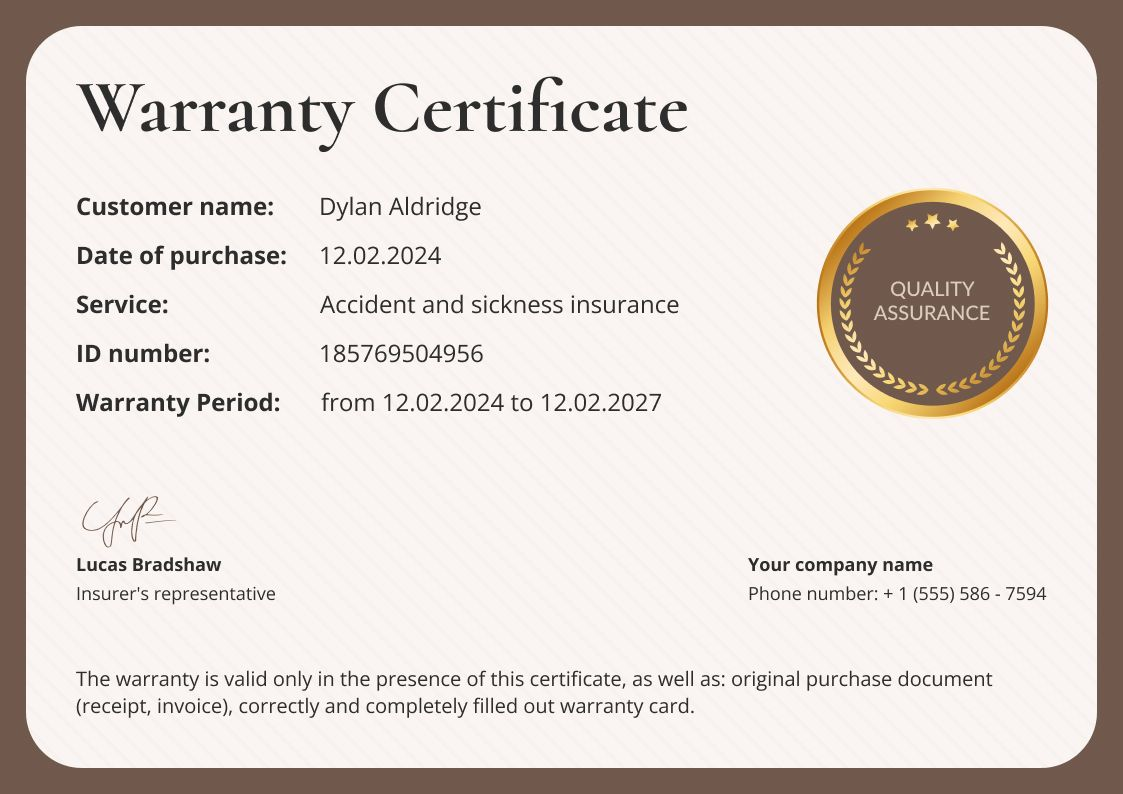
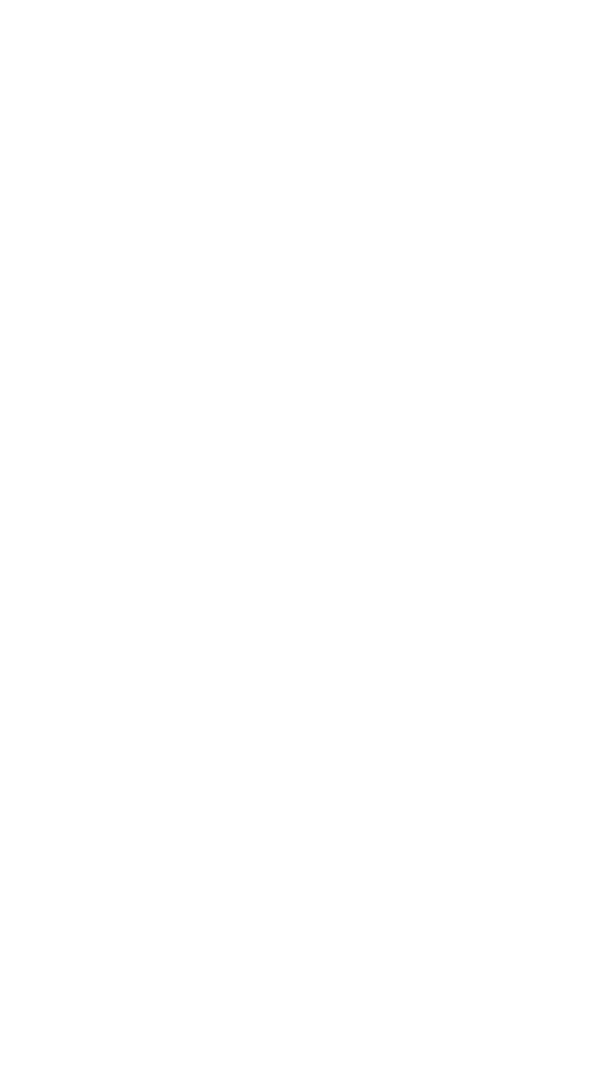
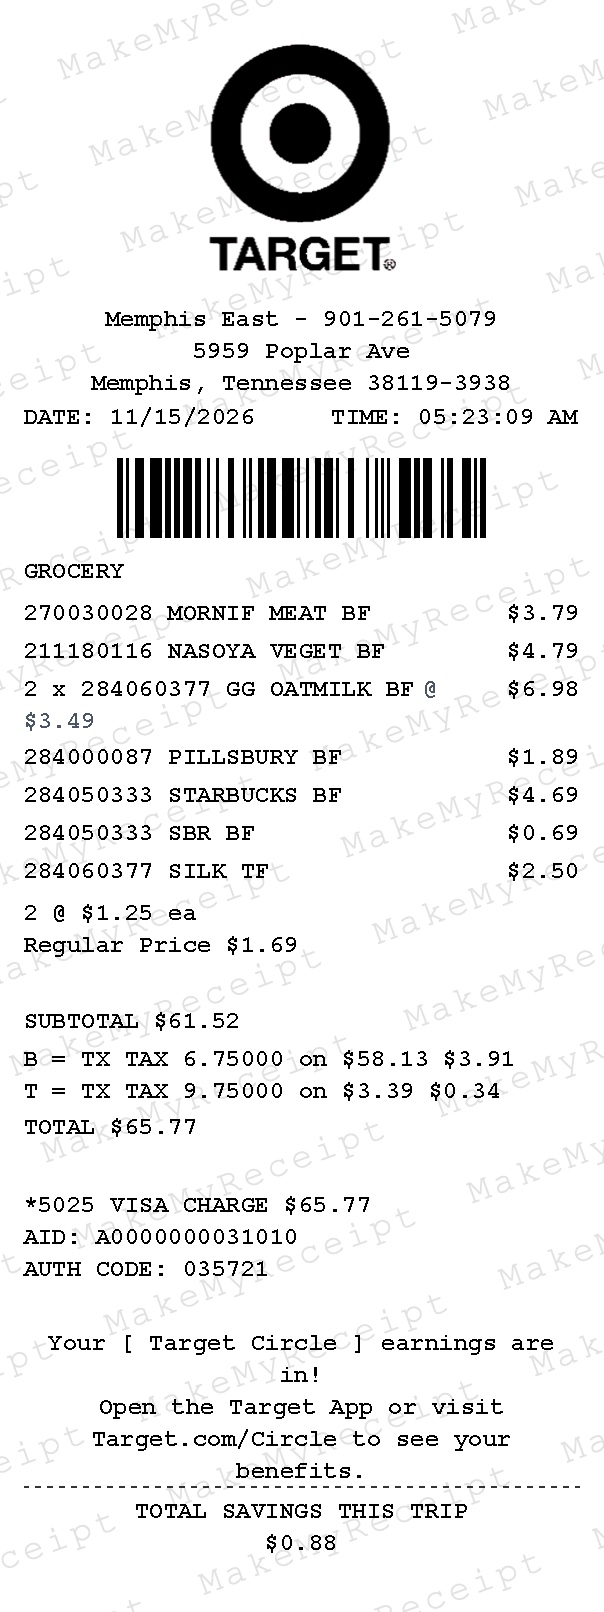

In [1]:
from pathlib import Path
import json
import sys
from IPython.display import HTML, display
sample_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
sample_lab = sample_root / 'services/llm/parsing'
if str(sample_lab) not in sys.path:
    sys.path.insert(0, str(sample_lab))
from review_gallery import notebook_cards
from run_generated_tests import validate_case
sample_manifest = json.loads((sample_lab / 'generated_test_manifest.json').read_text())
for sample_case in sample_manifest['cases']:
    validate_case(sample_case, sample_root)
sample_report = json.loads((sample_lab / 'generated_test_results.json').read_text())
for sample in sample_report['cases']:
    missing = [c['quote'] for c in sample['source_passage_checks'] if not c['resolves_after_whitespace_normalization']]
    print(sample['relative_path'], '| relevance:', sample['relevance']['outcome'],
          '| admitted:', sample['acceptance_gate'], '| unresolved source passages:', missing)
    print('Temporal assessment:', sample['temporal_state'])
    print('Review notes:', '; '.join(sample['source_review_notes']))
sample_gallery = json.loads((sample_lab / 'runs/generated-final/gallery-data.json').read_text())
display(HTML(notebook_cards(sample_gallery)))

## 14. Finalized stage and RAG input verification

Earlier notebook outputs are historical snapshots. The canonical closing record is `FINAL_STAGE_1.md`, with current measured JSON under `reports/`. The portable RAG handoff has reviewed acceptance-gate-approved synthetic fixtures, while excluding unapproved uploads and marking duplicate/review variants inactive. This verification performs no OCR, embeddings or paid calls.


In [2]:
from pathlib import Path
import json
import sys
final_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'Claimly_Three_Parts/contracts/llm.openapi.json').is_file())
final_lab = final_root / 'services/llm/parsing'
if str(final_lab) not in sys.path:
    sys.path.insert(0, str(final_lab))
from finalize_stage import verify_checkpoint
handoff = json.loads((final_lab / 'rag-handoff/index_input_manifest.json').read_text())
for item in handoff['documents']:
    verify_checkpoint(final_lab / 'rag-handoff' / item['checkpoint_path'])
print(json.dumps(json.loads((final_lab / 'reports/stage-summary.json').read_text()), indent=2))
print('Verified checkpoints:', handoff['checkpoint_count'])
print('Default active sources / chunks:', handoff['default_active_documents'], '/', handoff['default_active_chunks'])
print('Next-stage prompt: RAG_TESTING_PROMPT.md')

{
  "status": "Notebook/export experiment finalized; production not implemented or approved.",
  "baseline_cases": 55,
  "baseline_outcomes": {
    "uncertain": 11,
    "out_of_scope": 14,
    "unreadable": 2,
    "relevant": 20,
    "invalid_file": 8
  },
  "baseline_admitted": 19,
  "baseline_chunks": 21,
  "new_generated_cases": 3,
  "generated_admitted": 1,
  "human_review_count": 12,
  "human_prediction_matches": 5,
  "human_prediction_differences": 7,
  "rag_checkpoint_count": 20,
  "rag_default_active_documents": 12,
  "rag_default_active_chunks": 13,
  "rag_seed_queries": 12,
  "shared_contracts_changed": false,
  "paid_calls": 0,
  "embedding_calls": 0,
  "final_tests_passed": 61,
  "cleanup_removed_bytes": 162414968,
  "current_title_period_policy": "claimly-content-rules-v3-title-period"
}
Verified checkpoints: 20
Default active sources / chunks: 12 / 13
Next-stage prompt: RAG_TESTING_PROMPT.md
